# 02 — Distribución de clases y segmentos de ritmo

**Etapa I (PPS) / F2.** Consumo `results/inventario/ritmos.csv` (una fila por segmento de ritmo
anotado con `+`). Objetivos: cuantificar el desbalance de clases, y medir la distribución de
duraciones de los segmentos (base para definir "ritmo sostenido", AP-7).

In [1]:
%matplotlib inline
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(os.environ.get('PROJECT_ROOT',
                           Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
RES = ROOT / 'results'
FIG = RES / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(2026)

ritmos = pd.read_csv(RES / 'inventario' / 'ritmos.csv')
ritmos.head(3)


,registro,grupo,ritmo,clase,minutos
0,x001,pediatrico,(N,Sinusal,55.0892
1,x001,pediatrico,(N,Sinusal,0.6909
2,x001,pediatrico,(AVRT,SVT,0.2891


In [2]:
crudo = ritmos.groupby('ritmo').agg(segmentos=('ritmo', 'size'), minutos=('minutos', 'sum')).sort_values('minutos', ascending=False)
crudo.round(2)


,segmentos,minutos
ritmo,,
(N,1001,801.50
(/A,454,84.47
(AVRT,93,73.01
(/V,403,49.05
(AVNRT,126,44.92
(VT,99,28.34
(AFIB,12,8.17
(IVR,5,6.87
(A,13,4.98


In [3]:
tabla = (ritmos.pivot_table(index='clase', columns='grupo', values='minutos', aggfunc='sum', fill_value=0)
         .assign(total=lambda d: d.sum(axis=1)).sort_values('total', ascending=False).round(1))
tabla['%_ped'] = (tabla.pediatrico / tabla.pediatrico.sum() * 100).round(1)
tabla


grupo,adulto,pediatrico,total,%_ped
clase,,,,
Sinusal,184.0,617.5,801.5,71.1
SVT,2.1,132.0,134.2,15.2
Paced,16.4,117.2,133.5,13.5
VT,34.3,0.9,35.2,0.1
AFL,0.0,0.6,0.6,0.1
Otro,0.0,0.2,0.2,0.0


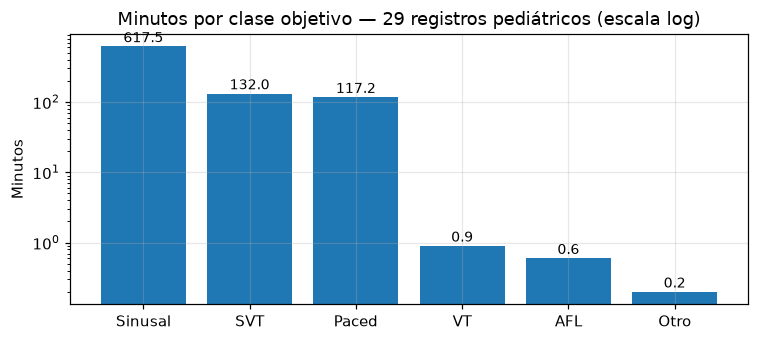

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ped = tabla.drop(columns='total')['pediatrico'].dropna()
ped = ped[ped > 0]
ax.bar(ped.index, ped.values, color='tab:blue')
ax.set_ylabel('Minutos'); ax.set_title('Minutos por clase objetivo — 29 registros pediátricos (escala log)')
ax.set_yscale('log')
for i, v in enumerate(ped.values):
    ax.text(i, v * 1.15, f'{v:.1f}', ha='center', fontsize=9)
fig.tight_layout(); fig.savefig(FIG / '02_minutos_por_clase_ped.png'); plt.show()


In [5]:
seg = ritmos[ritmos.grupo == 'pediatrico'].copy()
seg['segundos'] = seg.minutos * 60
est = seg.groupby('clase').agg(n_segmentos=('segundos', 'size'), mediana_s=('segundos', 'median'),
                               p10_s=('segundos', lambda s: s.quantile(0.10)), max_s=('segundos', 'max')).round(1)
est


,n_segmentos,mediana_s,p10_s,max_s
clase,,,,
AFL,1,37.3,37.3,37.3
Otro,2,5.4,3.9,7.2
Paced,650,4.6,2.0,634.4
SVT,268,9.7,2.2,613.7
Sinusal,727,5.2,1.7,3305.4
VT,12,2.1,1.5,15.6


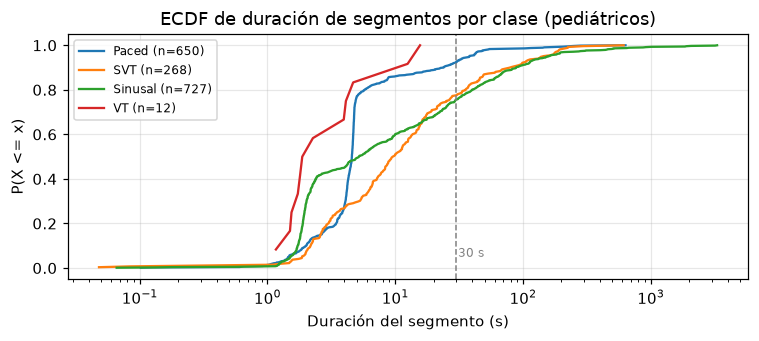

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for clase, sub in seg.groupby('clase'):
    if len(sub) >= 3:
        xs = np.sort(sub.segundos); ys = np.arange(1, len(xs) + 1) / len(xs)
        ax.plot(xs, ys, label=f'{clase} (n={len(xs)})')
ax.set_xscale('log'); ax.set_xlabel('Duración del segmento (s)'); ax.set_ylabel('P(X <= x)')
ax.set_title('ECDF de duración de segmentos por clase (pediátricos)')
ax.legend(fontsize=8); ax.axvline(30, color='gray', ls='--', lw=1)
ax.text(31, 0.05, '30 s', color='gray', fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '02_ecdf_segmentos.png'); plt.show()


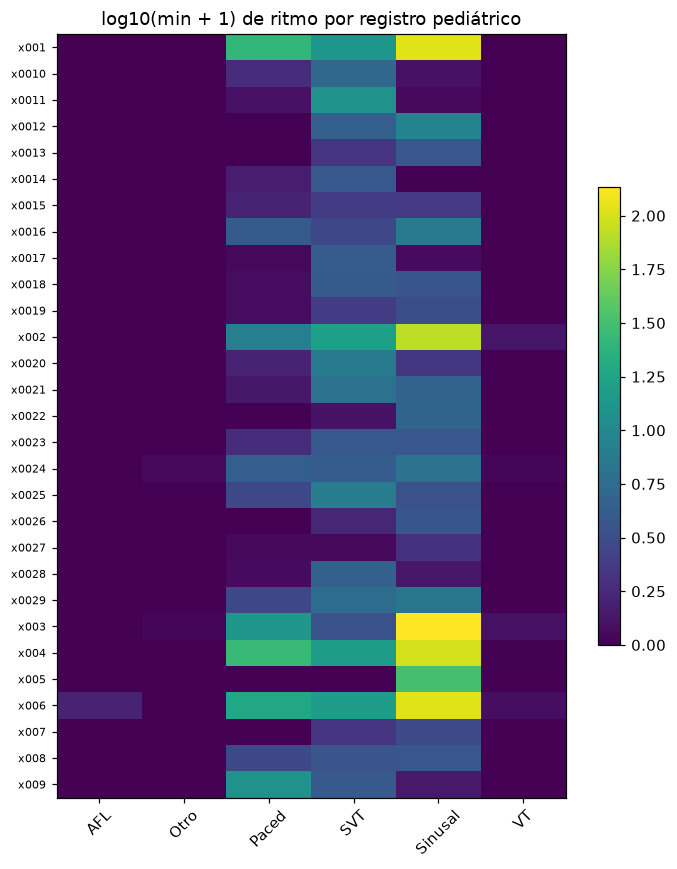

In [7]:
mat = seg.pivot_table(index='registro', columns='clase', values='minutos', aggfunc='sum', fill_value=0)
fig, ax = plt.subplots(figsize=(6.5, 8))
im = ax.imshow(np.log10(mat.values + 1), aspect='auto', cmap='viridis')
ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=45)
ax.set_yticks(range(mat.shape[0]), mat.index, fontsize=7)
ax.grid(False); ax.set_title('log10(min + 1) de ritmo por registro pediátrico')
fig.colorbar(im, ax=ax, shrink=0.6)
fig.tight_layout(); fig.savefig(FIG / '02_heatmap_registro_clase.png'); plt.show()


## Conclusiones

- **Desbalance severo** (escala log): Sinusal domina ~80% de los minutos pediátricos; VT y AFL
  son trazas marginales. Confirma AP-1: el KPI "F1 >= 0.80 por clase" es inalcanzable con 5
  clases en datos pediátricos.
- La ECDF de duraciones fundamenta AP-7: elegir el umbral de "segmento sostenido" donde haya
  masa suficiente por clase (línea de referencia 30 s).
- La matriz registro×clase muestra que varios registros aportan *mezclas* (ej. sinus + paced),
  útil para plantear validación por registro (leave-one-record-out).